In [1]:
%load_ext autoreload
%autoreload 2
import numpy as np
import emcee
import corner
from matplotlib import pyplot as plt
from matplotlib.patches import Patch
from matplotlib.ticker import MultipleLocator, FixedLocator
from astropy import units as u
from astropy import constants as const
import time
from multiprocessing import Pool
import pandas as pd
import pickle
import scipy
from matplotlib.lines import Line2D

from nfw_profile_heating import NFWProfile
from cluster_error_prop import Cluster_werr
from statistics_functions import log_lik
from load_data_and_var import load_data_and_var, generate_nfws_from_combined_dataset_werr
from plotting import savefig, paper_plot

In [9]:
dataset, variances = load_data_and_var()
dataset

,MCXC,OName,L500,Sub-Cat,RXC,Flux,e_Flux,ObsLum,LumCor,z_x,z_y,MSZ,E_MSZ,e_MSZ,L_err
1,J0003.8+0203,RXCJ0003.8+0203,0.846881,REFLEX,RXCJ0003.8+0203,4.155,18.8,0.855,0.929,0.0924,0.0924,2.238774,0.282160,0.301448,0.136707
2,J0006.0-3443,RXCJ0006.0-3443,1.809494,REFLEX,RXCJ0006.0-3443,5.832,13.6,1.875,1.995,0.1147,0.1147,4.001657,0.248869,0.226974,0.211627
3,J0011.3-2851,RXCJ0011.3-2851,1.086002,REFLEX,RXCJ0011.3-2851,12.014,9.0,1.089,1.197,0.0620,0.0620,2.606369,0.182667,0.188038,0.086428
4,J0013.6-1930,RXCJ0013.6-1930,1.236332,REFLEX,RXCJ0013.6-1930,6.071,11.3,1.285,1.353,0.0940,0.0940,2.756623,0.233331,0.245311,0.124160
5,J0014.3-6604,RXCJ0014.3-6604,2.827248,REFLEX,RXCJ0014.3-6604,4.485,13.8,2.907,3.160,0.1599,0.1599,3.030337,0.328876,0.347930,0.313974
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
219,J2344.2-0422,RXCJ2344.2-0422,1.852614,REFLEX,RXCJ2344.2-0422,12.638,7.4,1.855,2.061,0.0786,0.0786,3.116566,0.176734,0.208566,0.119209
220,J2347.7-2808,RXCJ2347.7-2808,1.029501,REFLEX,RXCJ2347.7-2808,49.578,3.8,1.014,1.127,0.0300,0.0300,1.480293,0.114748,0.107849,0.035784
222,J2354.2-1024,RXCJ2354.2-1024,1.336537,REFLEX,RXCJ2354.2-1024,9.622,12.1,1.337,1.469,0.0765,0.0765,2.761984,0.216913,0.225417,0.140721
223,J2357.0-3445,RXCJ2357.0-3445,1.629622,REFLEX,RXCJ2357.0-3445,32.663,5.5,1.698,1.787,0.0475,0.0475,2.468719,0.163126,0.149009,0.084855


In [12]:
nfws_werr=generate_nfws_from_combined_dataset_werr(dataset, variances, rmin=rmin)

In [30]:

cls_idx = 73
rmin = 0.001

nwalkers = 8
nsteps = 20000

In [14]:
nfws = [nfw for nfw in nfws_werr if nfw.z < 0.2]
nfws_subset = [nfw for nfw in nfws if nfw.energies.is_virialized_gaspari ]


In [15]:
len(nfws_subset)

111

In [18]:
print(nfws_subset[73].M500, nfws_subset[73].L500)

509226399999999.94 (+35620699999999.99, -36664999999999.99) 9.458634 ± 0.9693479406374533


In [20]:
nfws_subset = [[nfw for nfw in nfws if nfw.energies.is_virialized_gaspari ][73]]
L_obs = np.array([nfw.L500.value for nfw in nfws_subset])
variances_obs = np.array([nfw.L_err for nfw in nfws_subset])


In [23]:
# prepare MCMC

ndim = 2
initial=np.zeros((nwalkers, ndim ))

In [24]:
# initialize walkers
log_sigma0 = np.random.uniform(low=-40, high=-23, size=nwalkers).astype(np.float128)
#log_mp = np.log10(const.m_p.to(u.GeV, equivalencies=u.mass_energy()).value)
log_mx = np.random.uniform(low=-4, high=-1, size=nwalkers).astype(np.float128)

initial[:,0]=log_sigma0
initial[:,1]=log_mx

In [44]:
# burn in
with Pool() as pool:
    sampler = emcee.EnsembleSampler(nwalkers,
                            ndim,
                            log_lik,
                            args=[L_obs, nfws_subset, variances_obs, 1])
    state = sampler.run_mcmc(initial, 1000, progress=True)
    sampler.reset()

100%|██████████████████████████████████████| 1000/1000 [00:02<00:00, 398.68it/s]


In [45]:
#production run
with Pool() as pool:
    #start sampler after some steps to minimize dependence on initial conditions
    state_f = sampler.run_mcmc(state, nsteps, progress = True)


100%|████████████████████████████████████| 20000/20000 [00:56<00:00, 353.82it/s]


In [46]:
# create corner plot of results
flat_samples = sampler.get_chain(thin=15, flat=True)

print(flat_samples.shape)

(10664, 2)


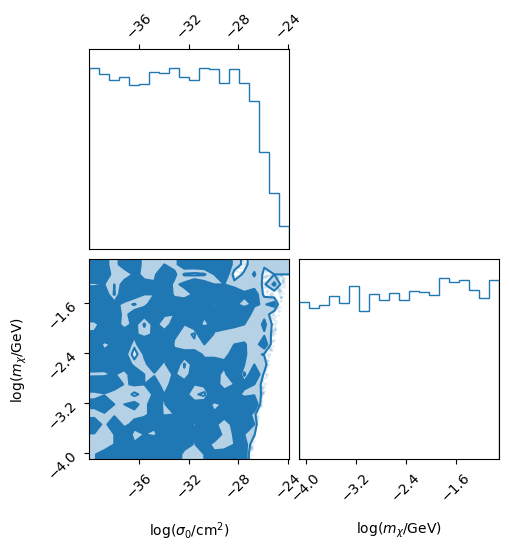

In [47]:
labels = [r"$\mathrm{log} (\sigma_0 / \mathrm{cm^2})$", r"$\mathrm{log} (m_\chi / \mathrm{GeV})$"]
fig = corner.corner(
        flat_samples, labels=labels,
        dpi=450, 
    #smooth=3.0, 
    levels=[0.68, 0.95], 
    top_ticks=True, 
    color='#1f77b4',
    fill_contours=True,
    plot_density=True,
    #contourf_kwargs={"alpha":0.5}, 
    scatter_kws={"alpha": 0}, 
    zorder=1
    )